# Modelagem preditiva da produtividade da safra de soja com uso de aprendizado de máquina e dados agrometeorológicos — Modelagem (Etapa 6: previsão da safra 2026 e perspectiva da safra 2027)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** aplica os modelos da Etapa 5 (clima do NASA POWER, patamar com as safras já publicadas na data da previsão: para 2026, até 2024) ao seu uso final: **prever a próxima safra**. (1) Estende o clima do NASA POWER até maio/2026 (complemento baixado por `dataset/baixar_nasa_power.py`) e o ONI até 2026; (2) reconfirma, com essa regra, a validação dos cinco modelos (linha de base, F, H2, FL e Gradient Boosting); (3) **prevê o rendimento da safra 2026** por município, como seria feito em março/2026 (patamar 2020–2024 + clima out/2025–mar/2026), com intervalo de erro tirado da validação, e compara com a estimativa do LSPA/IBGE (a PAM de 2026 só sai em set/2027); (4) monta a **perspectiva da safra 2027**: o patamar já é conhecido (2021–2025), mas o clima de dez/2026–mar/2027 ainda não aconteceu, então o modelo FL é aplicado com o clima de cada safra de 2006–2026 (cenários), destacando os anos de El Niño, fase em que o Pacífico está em out/2026. As previsões por município são salvas em `dataset/processed/previsao_safra_2026_municipio.csv` e `dataset/processed/perspectiva_safra_2027_municipio.csv`.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-10-29 |                 | Criação do notebook — validação Y−2 dos cinco modelos, previsão da safra 2026 por município (comparada ao LSPA) e perspectiva da safra 2027 por cenários climáticos |

## 1. Imports e configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RAW = "../dataset/raw"
PROCESSED = "../dataset/processed"

ANO_CORTE = 2020          # corte temporal: treino até 2020, teste 2021-2025
DEFASAGEM_PUBLICACAO = 2  # em 31/03/2026, a última PAM/IBGE publicada é a de 2024 (dois anos antes)
PRIMEIRA_SAFRA = 2006     # primeira safra com 5 safras publicadas para o patamar
SAFRA_PREVISAO = 2026     # safra prevista com o clima já observado (previsão de março/2026)
SAFRA_PERSPECTIVA = 2027  # safra em plantio (out/2026): clima ainda desconhecido
SEED = 42
LIMIAR_SECO_MM = 1.0      # dia seco: chuva < 1 mm
LIMIAR_CALOR_C = 32.0     # dia de calor: temperatura máxima >= 32 °C
CAD_MM = 75               # capacidade de água disponível no solo
PERCENTIL_LIMIAR = 0.2    # limiares de seca extrema: 20% mais secos do treino
LIMIAR_ENOS = 0.5         # |ONI médio da safra| >= 0,5: El Niño / La Niña

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Ambiente pronto.")

Ambiente pronto.


## 2. Dados: painel, clima do NASA POWER até maio/2026, ONI até 2026 e LSPA

O arquivo `nasa_power_rs_2000_2025.csv` termina em dez/2025, ou seja, já traz o início da safra 2026 (out–dez/2025). O complemento `nasa_power_rs_2026.csv` (jan–mai/2026) fecha a safra. O ONI de 2026 está em `noaa_oni_2026.csv`, e as estimativas de setembro do **LSPA** (Levantamento Sistemático da Produção Agrícola, IBGE, tabela 6588) estão em `ibge_sidra_6588_lspa_soja_rs.csv`.

In [2]:
def chave_celula(lat, lon):
    return lat.map("{:.3f}".format) + "_" + lon.map("{:.4f}".format)


power = pd.concat([pd.read_csv(f"{RAW}/nasa_power_rs_2000_2025.csv", parse_dates=["data"]),
                   pd.read_csv(f"{RAW}/nasa_power_rs_2026.csv", parse_dates=["data"])],
                  ignore_index=True)
mapa = pd.read_csv(f"{RAW}/nasa_power_celulas_municipios_rs.csv")
power["celula"] = chave_celula(power["lat_celula"], power["lon_celula"])
mapa["celula"] = chave_celula(mapa["lat_celula"], mapa["lon_celula"])
assert not power.duplicated(["celula", "data"]).any()

painel = pd.read_csv(f"{PROCESSED}/painel_municipio_safra.csv")
regioes = pd.read_csv(f"{RAW}/ibge_municipios_rs_regioes.csv",
                      usecols=["codigo_ibge_municipio", "mesorregiao"])
regioes["mesorregiao"] = regioes["mesorregiao"].str.replace(" Rio-grandense", "")

# ONI por safra, com a mesma regra da análise exploratória (OND/NDJ do ano anterior + DJF/JFM)
oni = pd.concat([pd.read_csv(f"{RAW}/noaa_oni_1999_2025.csv"), pd.read_csv(f"{RAW}/noaa_oni_2026.csv")])
JANELA = {"OND": 1, "NDJ": 1, "DJF": 0, "JFM": 0}
oni_safra = (oni[oni["seas"].isin(JANELA)]
             .assign(ano_safra=lambda d: d["ano"] + d["seas"].map(JANELA))
             .groupby("ano_safra")["oni_anom"].mean().rename("oni_media_safra"))
# Conferência: até 2025 o ONI calculado aqui é o mesmo do painel (a safra 2026 vem só daqui)
no_painel = painel.drop_duplicates("ano_safra").set_index("ano_safra")["oni_media_safra"]
assert np.allclose(no_painel, oni_safra.reindex(no_painel.index))

lspa = pd.read_csv(f"{RAW}/ibge_sidra_6588_lspa_soja_rs.csv")

ALVO = "rendimento_kg_ha"
ONI = "oni_media_safra"
CLIMA = ["chuva_out_nov", "chuva_dez_fev", "chuva_mar", "seca_max_dez_fev",
         "dias_calor_dez_fev", "tmax_dez_fev", "urmin_dez_fev"]
VAR_HIDRICO = ["deficit_dez_fev", "balanco_dez_fev", "eto_dez_fev"]
com_rendimento = painel.dropna(subset=[ALVO])

print(f"NASA POWER: {len(power):,} dias-célula | {power['celula'].nunique()} células | "
      f"{power['data'].min():%Y-%m-%d} a {power['data'].max():%Y-%m-%d} | "
      f"valores ausentes: {power.isna().sum().sum()}")
print(f"ONI médio da safra {SAFRA_PREVISAO}: {oni_safra[SAFRA_PREVISAO]:+.2f} | "
      f"última janela publicada: {oni.iloc[-1]['seas']}/{oni.iloc[-1]['ano']} = {oni.iloc[-1]['oni_anom']:+.2f}")

NASA POWER: 563,412 dias-célula | 87 células | 2000-01-01 a 2026-05-31 | valores ausentes: 0
ONI médio da safra 2026: -0.45 | última janela publicada: JAS/2026 = +2.16


## 3. Variáveis climáticas por célula e safra (2001–2026)

Mesmo cálculo da Etapa 5 (chuva por subperíodo, seca, calor, umidade mínima estimada e balanço hídrico diário com CAD de 75 mm), agora incluindo a safra 2026.

In [3]:
def pressao_saturacao(t):
    return 0.6108 * np.exp(17.27 * t / (t + 237.3))


power["urmin"] = (100 * pressao_saturacao(power["tdew_c"])
                  / pressao_saturacao(power["tmax_c"])).clip(upper=100)
mes = power["data"].dt.month
power["ano_safra"] = power["data"].dt.year + (mes >= 10)
power["subperiodo"] = pd.cut(mes.where(mes >= 4, mes + 12), bins=[3, 5, 9, 11, 14, 15],
                             labels=["abr_mai", "fora", "out_nov", "dez_fev", "mar"])
power = power[power["ano_safra"].between(2001, SAFRA_PREVISAO)].copy()
power["calor"] = power["tmax_c"] >= LIMIAR_CALOR_C

chaves = [power["celula"], power["ano_safra"], power["subperiodo"]]
g = power.groupby(chaves, observed=True)
sub = pd.DataFrame({"chuva": g["chuva_mm"].sum(), "tmax": g["tmax_c"].mean(),
                    "urmin": g["urmin"].mean(), "dias_calor": g["calor"].sum()})

seco = power["chuva_mm"] < LIMIAR_SECO_MM
bloco = (~seco).groupby(chaves, observed=True).cumsum()
sub["seca_max"] = (seco.groupby(chaves + [bloco], observed=True).sum()
                   .groupby(level=[0, 1, 2], observed=True).max())
sub.index.names = ["celula", "ano_safra", "subperiodo"]

wide = sub[["chuva"]].unstack("subperiodo")
wide.columns = [f"chuva_{s}" for s in wide.columns.get_level_values(1)]
dez_fev = sub.xs("dez_fev", level="subperiodo")[["seca_max", "dias_calor", "tmax", "urmin"]]
dez_fev.columns = [f"{c}_dez_fev" for c in dez_fev.columns]

hd = power[power["data"].dt.month.isin([10, 11, 12, 1, 2])].copy()
phi = np.radians(hd["lat_celula"])
J = hd["data"].dt.day_of_year
dr = 1 + 0.033 * np.cos(2 * np.pi * J / 365)
delta = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)
ws = np.arccos(-np.tan(phi) * np.tan(delta))
Ra = (24 * 60 / np.pi) * 0.0820 * dr * (ws * np.sin(phi) * np.sin(delta)
                                         + np.cos(phi) * np.cos(delta) * np.sin(ws))
amplitude = (hd["tmax_c"] - hd["tmin_c"]).clip(lower=0)
hd["eto"] = 0.0023 * 0.408 * Ra * ((hd["tmax_c"] + hd["tmin_c"]) / 2 + 17.8) * np.sqrt(amplitude)


def deficit_dez_fev(cad):
    # Modelo de balde diário (Etapa 4), uma coluna por célula
    partes = []
    for ano, g in hd.groupby("ano_safra"):
        P = g.pivot(index="data", columns="celula", values="chuva_mm").sort_index()
        E = g.pivot(index="data", columns="celula", values="eto").reindex_like(P)
        armazenado = np.full(P.shape[1], float(cad))
        deficit = np.empty(P.shape)
        for i, (p, e) in enumerate(zip(P.to_numpy(), E.to_numpy())):
            disponivel = armazenado + p
            etr = np.minimum(e, disponivel)
            deficit[i] = e - etr
            armazenado = np.minimum(cad, disponivel - etr)
        meses_criticos = P.index.month.isin([12, 1, 2])
        partes.append(pd.DataFrame({"celula": P.columns, "ano_safra": ano,
                                    "deficit_dez_fev": deficit[meses_criticos].sum(axis=0)}))
    return pd.concat(partes, ignore_index=True).set_index(["celula", "ano_safra"])


critico = hd[hd["data"].dt.month.isin([12, 1, 2])]
hidrico = (critico.assign(balanco=critico["chuva_mm"] - critico["eto"])
           .groupby(["celula", "ano_safra"])[["balanco", "eto"]].sum()
           .rename(columns={"balanco": "balanco_dez_fev", "eto": "eto_dez_fev"})
           .join(deficit_dez_fev(CAD_MM)))
clima_power = wide.join(dez_fev).join(hidrico).reset_index()

# Conferência: até 2025 as variáveis são as mesmas salvas pela Etapa 5
etapa5 = pd.read_csv(f"{PROCESSED}/clima_nasa_power_celula_safra.csv")
comp = etapa5.merge(clima_power, on=["celula", "ano_safra"], suffixes=("_e5", ""))
assert len(comp) == len(etapa5)
assert all(np.allclose(comp[f"{v}_e5"], comp[v]) for v in CLIMA + VAR_HIDRICO)

# Clima médio estadual (média das células com município produtor) por safra
celulas_soja = mapa[mapa["codigo_ibge_municipio"].isin(com_rendimento["codigo_ibge_municipio"])]["celula"].unique()
VAR_RESUMO = ["chuva_out_nov", "chuva_dez_fev", "chuva_mar", "dias_calor_dez_fev", "urmin_dez_fev",
              "deficit_dez_fev"]
clima_estado = (clima_power[clima_power["celula"].isin(celulas_soja)]
                .groupby("ano_safra")[VAR_RESUMO].mean())
clima_estado.loc["média 2006–2025"] = clima_estado.loc[PRIMEIRA_SAFRA:2025].mean()
clima_estado.loc[[2012, 2020, 2022, 2023, 2024, 2025, SAFRA_PREVISAO, "média 2006–2025"]].round(0)

,chuva_out_nov,chuva_dez_fev,chuva_mar,dias_calor_dez_fev,urmin_dez_fev,deficit_dez_fev
ano_safra,,,,,,
2012,196.00,269.00,49.00,34.00,46.00,289.00
2020,394.00,246.00,32.00,32.00,46.00,271.00
2022,176.00,228.00,160.00,51.00,40.00,364.00
2023,170.00,215.00,94.00,42.00,43.00,335.00
2024,524.00,349.00,121.00,19.00,58.00,115.00
2025,209.00,270.00,53.00,35.00,48.00,265.00
2026,161.00,281.00,71.00,33.00,47.00,245.00
média 2006–2025,295.00,368.00,112.00,24.00,52.00,170.00


## 4. Patamar e bases de modelagem

Em 31/03/2026, a última PAM publicada é a de 2024 (saiu em set/2025). Assim, o patamar de 2026 é a média de 2020–2024 de cada município. Em 31/03/2027 a última será a de 2025 (saiu em set/2026), e o patamar de 2027 é a média de 2021–2025. A base de treino é a da Etapa 5 (NASA POWER, todas as linhas com rendimento, 2006–2025).

In [4]:
rend = com_rendimento.pivot_table(index="ano_safra", columns="codigo_ibge_municipio", values=ALVO)
estado = rend.mean(axis=1)
partes = []
for ano in range(PRIMEIRA_SAFRA, SAFRA_PERSPECTIVA + 1):
    ultima = ano - DEFASAGEM_PUBLICACAO   # última safra publicada em março de `ano`
    j5, todos = rend.loc[ultima - 4:ultima], rend.loc[:ultima]
    partes.append(pd.DataFrame({
        "ano_safra": ano,
        "patamar_mm5": j5.mean().where(j5.count() >= 3, estado.loc[ultima - 4:ultima].mean()),
        "base_media_hist": todos.mean().where(todos.count() >= 3, estado.loc[:ultima].mean()),
    }))
patamares = pd.concat(partes).rename_axis("codigo_ibge_municipio").reset_index()

OBRIGATORIAS = [ALVO, ONI, "patamar_mm5", "base_media_hist"] + CLIMA + VAR_HIDRICO
CHAVE = ["codigo_ibge_municipio", "ano_safra"]
celula_muni = mapa[["codigo_ibge_municipio", "celula"]]

base = (painel.merge(celula_muni, on="codigo_ibge_municipio")
        .merge(clima_power, on=["celula", "ano_safra"], how="left")
        .merge(patamares, on=CHAVE, how="left")
        .dropna(subset=OBRIGATORIAS))
base = base[base["ano_safra"] >= PRIMEIRA_SAFRA].reset_index(drop=True)
base["desvio"] = base[ALVO] - base["patamar_mm5"]

# Municípios previstos: os que colheram soja na última PAM disponível (2025)
ultima_pam = com_rendimento[com_rendimento["ano_safra"] == 2025]
municipios = (ultima_pam[["codigo_ibge_municipio", "municipio", "area_plantada_ha"]]
              .rename(columns={"area_plantada_ha": "area_plantada_2025_ha"})
              .merge(celula_muni, on="codigo_ibge_municipio")
              .merge(regioes, on="codigo_ibge_municipio", how="left"))


def alvo_safra(ano, ano_clima=None):
    # Linhas a prever: municípios × safra `ano`, com o clima da safra `ano_clima` (cenário)
    ano_clima = ano if ano_clima is None else ano_clima
    d = (municipios.assign(ano_safra=ano)
         .merge(patamares, on=CHAVE, how="left")
         .merge(clima_power[clima_power["ano_safra"] == ano_clima].drop(columns="ano_safra"),
                on="celula", how="left"))
    d[ONI] = oni_safra.get(ano_clima, np.nan)
    return d.assign(ano_clima=ano_clima)


alvo_2026 = alvo_safra(SAFRA_PREVISAO)
assert alvo_2026[["patamar_mm5"] + CLIMA + VAR_HIDRICO].notna().all().all()
print(f"Base de treino: {len(base)} linhas | {base['codigo_ibge_municipio'].nunique()} municípios | "
      f"safras {base['ano_safra'].min()}–{base['ano_safra'].max()}")
print(f"Municípios previstos (colheram soja em 2025): {len(municipios)} | "
      f"área plantada em 2025: {municipios['area_plantada_2025_ha'].sum():,.0f} ha")
print(f"Patamar médio — 2026 (2020–2024): {patamares.query('ano_safra == 2026')['patamar_mm5'].mean():,.0f} kg/ha | "
      f"2027 (2021–2025): {patamares.query('ano_safra == 2027')['patamar_mm5'].mean():,.0f} kg/ha")

Base de treino: 8261 linhas | 449 municípios | safras 2006–2025
Municípios previstos (colheram soja em 2025): 434 | área plantada em 2025: 6,796,591 ha
Patamar médio — 2026 (2020–2024): 2,392 kg/ha | 2027 (2021–2025): 2,443 kg/ha


## 5. Modelos e validação com o patamar das safras publicadas

Os cinco modelos da Etapa 5, sem mudança nas variáveis: **linha de base** (média histórica do município), **F** (patamar + OLS com chuva por subperíodo, calor e umidade mínima), **H2** (F + déficit hídrico e limiares), **FL** (F + limiar de déficit, o modelo final da Etapa 5) e **GB** (Gradient Boosting com todas as variáveis climáticas e o ONI). A Etapa 5 escolheu o FL com o patamar ainda incluindo a safra anterior (para 2026, 2021–2025, com 2025 ainda não publicada em março); aqui a escolha é refeita só com as safras publicadas (para 2026, 2020–2024), nas mesmas duas validações (corte 2021–2025 e deixa uma safra de fora).

In [5]:
FEAT_F = ["chuva_out_nov_100", "chuva_dez_fev_c100", "chuva_dez_fev_c100_2", "chuva_mar_100",
          "dias_calor_dez_fev", "urmin_dez_fev"]
FEAT_H2 = FEAT_F + ["deficit_100", "limiar_urmin", "limiar_deficit_100"]
FEAT_FL = FEAT_F + ["limiar_deficit_100"]
FEAT_GB = CLIMA + [ONI] + VAR_HIDRICO
BASE_HIST = "Linha de base: média histórica"
FINAL = "FL - F + limiar de déficit"
MODELOS = [BASE_HIST, "F - Final Etapa 3", "H2 - Final Etapa 4", FINAL, "GB - Gradient Boosting"]
LINEARES = {"F - Final Etapa 3": FEAT_F, "H2 - Final Etapa 4": FEAT_H2, FINAL: FEAT_FL}


def derivar(d, ref):
    d = d.copy()
    d["chuva_out_nov_100"] = d["chuva_out_nov"] / 100
    d["chuva_dez_fev_c100"] = (d["chuva_dez_fev"] - ref["chuva"]) / 100
    d["chuva_dez_fev_c100_2"] = d["chuva_dez_fev_c100"] ** 2
    d["chuva_mar_100"] = d["chuva_mar"] / 100
    d["deficit_100"] = d["deficit_dez_fev"] / 100
    d["limiar_urmin"] = (ref["urmin"] - d["urmin_dez_fev"]).clip(lower=0)
    d["limiar_deficit_100"] = (d["deficit_dez_fev"] - ref["deficit"]).clip(lower=0) / 100
    return d


def referencias(tr):
    return {"chuva": tr["chuva_dez_fev"].mean(),
            "urmin": tr["urmin_dez_fev"].quantile(PERCENTIL_LIMIAR),
            "deficit": tr["deficit_dez_fev"].quantile(1 - PERCENTIL_LIMIAR)}


def gb():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, min_samples_leaf=20,
                                         early_stopping=True, validation_fraction=0.1,
                                         random_state=SEED)


def ajustar(tr):
    # Treina os modelos e devolve uma função que prevê qualquer base com as mesmas colunas
    ref = referencias(tr)
    trd = derivar(tr, ref)
    lineares = {n: LinearRegression().fit(trd[f], trd["desvio"]) for n, f in LINEARES.items()}
    boosting = gb().fit(trd[FEAT_GB], trd["desvio"])

    def prever(te):
        ted = derivar(te, ref)
        pat = ted["patamar_mm5"].to_numpy()
        saida = {BASE_HIST: ted["base_media_hist"].to_numpy()}
        for n, m in lineares.items():
            saida[n] = pat + m.predict(ted[LINEARES[n]])
        saida["GB - Gradient Boosting"] = pat + boosting.predict(ted[FEAT_GB])
        return saida
    return prever


def validar(base):
    ident = base[CHAVE + [ALVO, "patamar_mm5", "area_plantada_ha"]]
    tr, te = base[base["ano_safra"] <= ANO_CORTE], base[base["ano_safra"] > ANO_CORTE]
    corte = ident.loc[te.index].assign(**ajustar(tr)(te))
    partes = []
    for ano in [a for a in sorted(base["ano_safra"].unique()) if a >= 2008]:
        tr, te = base[base["ano_safra"] != ano], base[base["ano_safra"] == ano]
        partes.append(ident.loc[te.index].assign(**ajustar(tr)(te)))
    return corte, pd.concat(partes)


def metricas(y, pred):
    return {"RMSE (kg/ha)": mean_squared_error(y, pred) ** 0.5,
            "MAE (kg/ha)": mean_absolute_error(y, pred),
            "R²": r2_score(y, pred),
            "Viés (kg/ha)": np.mean(pred - y)}


corte, loyo = validar(base)
validacao = pd.concat({"Corte 2021–2025": pd.DataFrame({m: metricas(corte[ALVO], corte[m]) for m in MODELOS}).T,
                       "Deixa uma safra de fora": pd.DataFrame({m: metricas(loyo[ALVO], loyo[m]) for m in MODELOS}).T},
                      axis=1)
validacao[("Média", "RMSE (kg/ha)")] = (validacao[("Corte 2021–2025", "RMSE (kg/ha)")]
                                       + validacao[("Deixa uma safra de fora", "RMSE (kg/ha)")]) / 2
validacao = validacao.sort_values(("Média", "RMSE (kg/ha)"))
validacao.style.format({c: ("{:.3f}" if c[1] == "R²" else "{:+.0f}" if c[1].startswith("Viés") else "{:.0f}")
                        for c in validacao.columns})

### Erro na média estadual

Para o produtor e para o planejamento da safra, o número mais usado é o **rendimento médio do estado**. Ele é calculado como na PAM, ponderando cada município pela área (aqui, a área plantada da própria safra). O erro estadual de cada safra na validação "deixa uma safra de fora" dá o intervalo usado nas previsões das seções 6 e 7.

In [6]:
def media_estado(d, colunas, peso="area_plantada_ha"):
    return d.groupby("ano_safra").apply(
        lambda g: pd.Series({c: np.average(g[c], weights=g[peso]) for c in colunas}), include_groups=False)


estado_loyo = media_estado(loyo, [ALVO] + MODELOS)
erro_estado = estado_loyo[MODELOS].sub(estado_loyo[ALVO], axis=0)
resumo_estado = pd.DataFrame({
    "MAE da média estadual (kg/ha)": erro_estado.abs().mean(),
    "maior erro (kg/ha)": erro_estado.abs().max(),
    "correlação com o observado": estado_loyo[MODELOS].corrwith(estado_loyo[ALVO]),
}).loc[validacao.index]
display(resumo_estado.round(2))

# Referência: quanto o LSPA de setembro erra a PAM, no mesmo período
pam_estado = (com_rendimento.groupby("ano_safra")
              .apply(lambda g: 1000 * g["producao_ton"].sum() / g["area_colhida_ha"].sum(), include_groups=False)
              .rename("PAM (kg/ha)"))
lspa_set = lspa[lspa["periodo_levantamento"] % 100 == 9].set_index("ano_safra")["rendimento_kg_ha"]
lspa_x_pam = pd.DataFrame({"PAM (kg/ha)": pam_estado, "LSPA de setembro (kg/ha)": lspa_set}).dropna()
lspa_x_pam["diferença (kg/ha)"] = lspa_x_pam["LSPA de setembro (kg/ha)"] - lspa_x_pam["PAM (kg/ha)"]
print(f"LSPA de setembro × PAM (2007–2025): MAE {lspa_x_pam['diferença (kg/ha)'].abs().mean():.0f} kg/ha | "
      f"maior diferença {lspa_x_pam['diferença (kg/ha)'].abs().max():.0f} kg/ha")
lspa_x_pam.loc[2018:].round(0)

,MAE da média estadual (kg/ha),maior erro (kg/ha),correlação com o observado
FL - F + limiar de déficit,244.10,772.15,0.85
H2 - Final Etapa 4,251.16,731.26,0.85
F - Final Etapa 3,261.54,825.82,0.84
GB - Gradient Boosting,347.26,"1,139.02",0.66
Linha de base: média histórica,690.37,"1,276.48",0.05


LSPA de setembro × PAM (2007–2025): MAE 7 kg/ha | maior diferença 35 kg/ha


,PAM (kg/ha),LSPA de setembro (kg/ha),diferença (kg/ha)
ano_safra,,,
2018,"3,104.00","3,103.00",-1.00
2019,"3,179.00","3,178.00",-1.00
2020,"1,886.00","1,882.00",-4.00
2021,"3,343.00","3,344.00",1.00
2022,"1,508.00","1,503.00",-5.00
2023,"1,912.00","1,912.00",0.00
2024,"2,806.00","2,811.00",5.00
2025,"2,012.00","2,009.00",-3.00


## 6. Previsão da safra 2026

Os cinco modelos são treinados com todas as safras 2006–2025 e aplicados ao clima de out/2025–mar/2026. É a previsão que estaria disponível em **abril/2026**, logo depois do fim de março (último subperíodo usado), antes da colheita terminar. O intervalo de 80% da média estadual vem dos percentis 10 e 90 do erro estadual na validação "deixa uma safra de fora" (seção 5); o de cada município, dos percentis 10 e 90 do erro municipal.

In [7]:
prever = ajustar(base)
prev_2026 = alvo_2026.assign(**prever(alvo_2026))
q_estado = erro_estado.quantile([0.1, 0.9])

previsao_estado = pd.DataFrame({
    "previsão (kg/ha)": [np.average(prev_2026[m], weights=prev_2026["area_plantada_2025_ha"]) for m in MODELOS],
}, index=MODELOS)
previsao_estado["intervalo 80% — de"] = previsao_estado["previsão (kg/ha)"] - q_estado.loc[0.9]
previsao_estado["intervalo 80% — até"] = previsao_estado["previsão (kg/ha)"] - q_estado.loc[0.1]
previsao_estado = previsao_estado.loc[validacao.index]
lspa_2026 = lspa.set_index("periodo_levantamento").loc[[202603, 202609], "rendimento_kg_ha"]
patamar_2026 = np.average(prev_2026["patamar_mm5"], weights=prev_2026["area_plantada_2025_ha"])
print(f"Patamar 2026 (média 2020–2024, ponderada pela área): {patamar_2026:,.0f} kg/ha")
print(f"LSPA/IBGE para 2026 — mar/2026: {lspa_2026[202603]:,} kg/ha | set/2026: {lspa_2026[202609]:,} kg/ha")
previsao_estado.round(0)

Patamar 2026 (média 2020–2024, ponderada pela área): 2,270 kg/ha
LSPA/IBGE para 2026 — mar/2026: 2,742 kg/ha | set/2026: 2,734 kg/ha


,previsão (kg/ha),intervalo 80% — de,intervalo 80% — até
FL - F + limiar de déficit,"2,097.00","1,685.00","2,430.00"
H2 - Final Etapa 4,"2,094.00","1,649.00","2,473.00"
F - Final Etapa 3,"2,045.00","1,672.00","2,387.00"
GB - Gradient Boosting,"2,221.00","1,517.00","2,682.00"
Linha de base: média histórica,"2,276.00","1,833.00","3,266.00"


### Por que o FL prevê esse valor: contribuição de cada fator em 2026

Como o FL é linear, a previsão de cada município é o patamar mais a soma das contribuições de cada variável climática (coeficiente × diferença para a média do treino, como na Figura 4 da Etapa 5).

In [8]:
ref = referencias(base)
completa = derivar(base, ref)
fl = LinearRegression().fit(completa[FEAT_FL], completa["desvio"])
FATORES = {"Chuva out–nov": ["chuva_out_nov_100"],
           "Chuva dez–fev": ["chuva_dez_fev_c100", "chuva_dez_fev_c100_2"],
           "Chuva março": ["chuva_mar_100"],
           "Dias de calor dez–fev": ["dias_calor_dez_fev"],
           "Umidade mínima dez–fev": ["urmin_dez_fev"],
           "Seca extrema (déficit acima do limiar)": ["limiar_deficit_100"]}


def contribuicoes(d):
    c = derivar(d, ref)[FEAT_FL].sub(completa[FEAT_FL].mean()).mul(pd.Series(fl.coef_, index=FEAT_FL))
    c = pd.DataFrame({f: c[cols].sum(axis=1) for f, cols in FATORES.items()})
    return c.apply(lambda col: np.average(col, weights=d["area_plantada_2025_ha"]))


contrib_2026 = contribuicoes(alvo_2026)
contrib_2026["Desvio médio do treino (intercepto)"] = completa["desvio"].mean()
contrib_2026["Total em relação ao patamar"] = contrib_2026.sum()
contrib_2026.round(0).to_frame("contribuição (kg/ha)")

,contribuição (kg/ha)
Chuva out–nov,62.00
Chuva dez–fev,-284.00
Chuva março,-19.00
Dias de calor dez–fev,24.00
Umidade mínima dez–fev,-103.00
Seca extrema (déficit acima do limiar),-5.00
Desvio médio do treino (intercepto),153.00
Total em relação ao patamar,-173.00


### Previsão de 2026 por mesorregião

In [9]:
erro_muni = loyo[FINAL] - loyo[ALVO]
q_muni = erro_muni.quantile([0.1, 0.9])
saida_2026 = prev_2026[["codigo_ibge_municipio", "municipio", "mesorregiao", "area_plantada_2025_ha",
                        "patamar_mm5"] + VAR_RESUMO].copy()
saida_2026["previsao_fl_kg_ha"] = prev_2026[FINAL]
saida_2026["intervalo80_de_kg_ha"] = prev_2026[FINAL] - q_muni.loc[0.9]
saida_2026["intervalo80_ate_kg_ha"] = prev_2026[FINAL] - q_muni.loc[0.1]
for m, col in [(BASE_HIST, "previsao_media_hist_kg_ha"), ("F - Final Etapa 3", "previsao_f_kg_ha"),
               ("H2 - Final Etapa 4", "previsao_h2_kg_ha"), ("GB - Gradient Boosting", "previsao_gb_kg_ha")]:
    saida_2026[col] = prev_2026[m]
previsoes = [c for c in saida_2026.columns if c.startswith(("previsao_", "intervalo80_"))]
saida_2026[previsoes] = saida_2026[previsoes].clip(lower=0)   # rendimento não fica negativo
saida_2026 = saida_2026.rename(columns={"patamar_mm5": "patamar_2020_2024_kg_ha"})
saida_2026.round(0).to_csv(f"{PROCESSED}/previsao_safra_2026_municipio.csv", index=False)

por_meso = saida_2026.groupby("mesorregiao").apply(lambda g: pd.Series({
    "municípios": len(g),
    "área plantada 2025 (mil ha)": g["area_plantada_2025_ha"].sum() / 1000,
    "patamar 2020–2024 (kg/ha)": np.average(g["patamar_2020_2024_kg_ha"], weights=g["area_plantada_2025_ha"]),
    "previsão FL 2026 (kg/ha)": np.average(g["previsao_fl_kg_ha"], weights=g["area_plantada_2025_ha"]),
}), include_groups=False).sort_values("área plantada 2025 (mil ha)", ascending=False)
por_meso["variação sobre o patamar"] = por_meso["previsão FL 2026 (kg/ha)"] / por_meso["patamar 2020–2024 (kg/ha)"] - 1
print(f"Salvo em {PROCESSED}/previsao_safra_2026_municipio.csv ({len(saida_2026)} municípios)")
print(f"Intervalo de 80% por município: previsão {-q_muni.loc[0.9]:+.0f} a {-q_muni.loc[0.1]:+.0f} kg/ha")
por_meso.style.format({"municípios": "{:.0f}", "área plantada 2025 (mil ha)": "{:,.0f}",
                       "patamar 2020–2024 (kg/ha)": "{:,.0f}", "previsão FL 2026 (kg/ha)": "{:,.0f}",
                       "variação sobre o patamar": "{:+.0%}"})

Salvo em ../dataset/processed/previsao_safra_2026_municipio.csv (434 municípios)
Intervalo de 80% por município: previsão -851 a +670 kg/ha


,municípios,área plantada 2025 (mil ha),patamar 2020–2024 (kg/ha),previsão FL 2026 (kg/ha),variação sobre o patamar
mesorregiao,,,,,
Noroeste,216,"3,295","2,470","2,438",-1%
Sudoeste,19,"1,076","1,729","1,105",-36%
Centro Ocidental,31,926,"2,036","2,130",+5%
Sudeste,25,632,"2,104","1,549",-26%
Nordeste,43,348,"2,998","2,775",-7%
Centro Oriental,51,327,"2,124","1,945",-8%
Metropolitana de Porto Alegre,49,192,"2,470","2,501",+1%


## 7. Perspectiva da safra 2027

Em out/2026 a soja de 2027 está sendo semeada. O **patamar já é conhecido** (2021–2025, ponderado pela área), mas o clima de dez/2026–mar/2027, que é o que mais pesa no FL, **ainda não aconteceu**. Não dá para prever o clima com o modelo; o que dá é montar **cenários**: o FL é aplicado ao patamar de 2027 com o clima observado em cada célula em cada uma das safras 2006–2026 (21 cenários). A distribuição resultante é a perspectiva para 2027 no plantio.

O mesmo exercício, feito para 2026 com o patamar de 2026, mostra o que se diria de 2026 no plantio (out/2025) e permite comparar com a previsão de março (seção 6).

Os cenários são separados pela fase do ENOS na safra de origem (ONI médio out–mar ≥ +0,5: El Niño; ≤ −0,5: La Niña). Em out/2026 o ONI está em +2,2 (JAS/2026) e subindo, então a safra 2027 deve ocorrer sob **El Niño**, que no RS costuma trazer chuva acima da média no verão.

In [10]:
ANOS_CENARIO = list(range(PRIMEIRA_SAFRA, SAFRA_PREVISAO + 1))


def fase_enos(v):
    return "El Niño" if v >= LIMIAR_ENOS else "La Niña" if v <= -LIMIAR_ENOS else "Neutro"


def cenarios(ano):
    linhas = []
    for ano_clima in ANOS_CENARIO:
        d = alvo_safra(ano, ano_clima)
        d[FINAL] = prever(d)[FINAL]
        linhas.append({"clima da safra": ano_clima, "ONI da safra": oni_safra[ano_clima],
                       "fase do ENOS": fase_enos(oni_safra[ano_clima]),
                       f"FL {ano} (kg/ha)": np.average(d[FINAL], weights=d["area_plantada_2025_ha"])})
    return pd.DataFrame(linhas).set_index("clima da safra")


cen_2027 = cenarios(SAFRA_PERSPECTIVA)
cen_2026 = cenarios(SAFRA_PREVISAO)
cen = cen_2027.join(cen_2026[[f"FL {SAFRA_PREVISAO} (kg/ha)"]])
patamar_2027 = np.average(alvo_safra(SAFRA_PERSPECTIVA)["patamar_mm5"],
                          weights=municipios["area_plantada_2025_ha"])
print(f"Patamar 2027 (média 2021–2025, ponderada pela área): {patamar_2027:,.0f} kg/ha "
      f"({patamar_2027 - patamar_2026:+,.0f} em relação ao de 2026)")
cen.sort_values(f"FL {SAFRA_PERSPECTIVA} (kg/ha)").style.format(
    {"ONI da safra": "{:+.2f}", f"FL {SAFRA_PERSPECTIVA} (kg/ha)": "{:,.0f}", f"FL {SAFRA_PREVISAO} (kg/ha)": "{:,.0f}"})

Patamar 2027 (média 2021–2025, ponderada pela área): 2,300 kg/ha (+30 em relação ao de 2026)


,ONI da safra,fase do ENOS,FL 2027 (kg/ha),FL 2026 (kg/ha)
clima da safra,,,,
2022,-0.80,La Niña,"1,195","1,164"
2023,-0.60,La Niña,"1,239","1,209"
2012,-0.80,La Niña,"1,623","1,592"
2020,+0.71,El Niño,"1,746","1,715"
2025,-0.35,Neutro,"1,897","1,866"
2006,-0.76,La Niña,"2,013","1,983"
2026,-0.45,Neutro,"2,128","2,097"
2008,-1.67,La Niña,"2,271","2,241"
2009,-0.77,La Niña,"2,273","2,242"


In [11]:
def resumo_cenarios(c, col):
    linhas = {"Todos os cenários": c[col]}
    for fase in ["El Niño", "Neutro", "La Niña"]:
        linhas[fase] = c.loc[c["fase do ENOS"] == fase, col]
    return pd.DataFrame({n: {"cenários": len(s), "mínimo": s.min(), "percentil 10": s.quantile(0.1),
                             "mediana": s.median(), "percentil 90": s.quantile(0.9), "máximo": s.max()}
                         for n, s in linhas.items()}).T


perspectiva = pd.concat({f"Safra {SAFRA_PERSPECTIVA}": resumo_cenarios(cen, f"FL {SAFRA_PERSPECTIVA} (kg/ha)"),
                         f"Safra {SAFRA_PREVISAO} (vista no plantio)": resumo_cenarios(cen, f"FL {SAFRA_PREVISAO} (kg/ha)")})
perspectiva.style.format("{:,.0f}")

In [12]:
# Perspectiva por município: mediana e faixa dos cenários de El Niño, e de todos os cenários
anos_nino = cen.index[cen["fase do ENOS"] == "El Niño"].tolist()
por_muni = pd.concat([alvo_safra(SAFRA_PERSPECTIVA, a).assign(fl=lambda d: prever(d)[FINAL].clip(min=0))
                      for a in ANOS_CENARIO])
g_todos = por_muni.groupby("codigo_ibge_municipio")["fl"]
g_nino = por_muni[por_muni["ano_clima"].isin(anos_nino)].groupby("codigo_ibge_municipio")["fl"]
saida_2027 = (municipios[["codigo_ibge_municipio", "municipio", "mesorregiao", "area_plantada_2025_ha"]]
              .merge(patamares.query("ano_safra == @SAFRA_PERSPECTIVA")[["codigo_ibge_municipio", "patamar_mm5"]]
                     .rename(columns={"patamar_mm5": "patamar_2021_2025_kg_ha"}), on="codigo_ibge_municipio")
              .set_index("codigo_ibge_municipio")
              .assign(fl_todos_p10_kg_ha=g_todos.quantile(0.1), fl_todos_mediana_kg_ha=g_todos.median(),
                      fl_todos_p90_kg_ha=g_todos.quantile(0.9),
                      fl_el_nino_min_kg_ha=g_nino.min(), fl_el_nino_mediana_kg_ha=g_nino.median(),
                      fl_el_nino_max_kg_ha=g_nino.max())
              .reset_index())
saida_2027.round(0).to_csv(f"{PROCESSED}/perspectiva_safra_2027_municipio.csv", index=False)
print(f"Cenários de El Niño: {anos_nino}")
print(f"Salvo em {PROCESSED}/perspectiva_safra_2027_municipio.csv ({len(saida_2027)} municípios)")

meso_2027 = saida_2027.groupby("mesorregiao").apply(lambda g: pd.Series({
    c: np.average(g[c], weights=g["area_plantada_2025_ha"])
    for c in ["patamar_2021_2025_kg_ha", "fl_todos_p10_kg_ha", "fl_todos_mediana_kg_ha", "fl_todos_p90_kg_ha",
              "fl_el_nino_mediana_kg_ha"]}), include_groups=False)
meso_2027 = meso_2027.loc[por_meso.index]
meso_2027.columns = ["patamar 2021–2025", "todos — percentil 10", "todos — mediana", "todos — percentil 90",
                     "El Niño — mediana"]
meso_2027.round(0)

Cenários de El Niño: [2007, 2010, 2015, 2016, 2019, 2020, 2024]
Salvo em ../dataset/processed/perspectiva_safra_2027_municipio.csv (434 municípios)


,patamar 2021–2025,todos — percentil 10,todos — mediana,todos — percentil 90,El Niño — mediana
mesorregiao,,,,,
Noroeste,"2,464.00","1,730.00","2,726.00","3,306.00","3,102.00"
Sudoeste,"1,749.00",554.00,"1,756.00","2,475.00","2,358.00"
Centro Ocidental,"1,999.00",953.00,"2,198.00","2,765.00","2,610.00"
Sudeste,"2,295.00","1,328.00","2,344.00","2,819.00","2,560.00"
Nordeste,"3,121.00","2,928.00","3,455.00","3,959.00","3,824.00"
Centro Oriental,"2,276.00","1,517.00","2,358.00","2,993.00","2,809.00"
Metropolitana de Porto Alegre,"2,600.00","2,025.00","2,704.00","3,167.00","2,961.00"


## 8. Visão geral: série estadual, previsão de 2026 e perspectiva de 2027

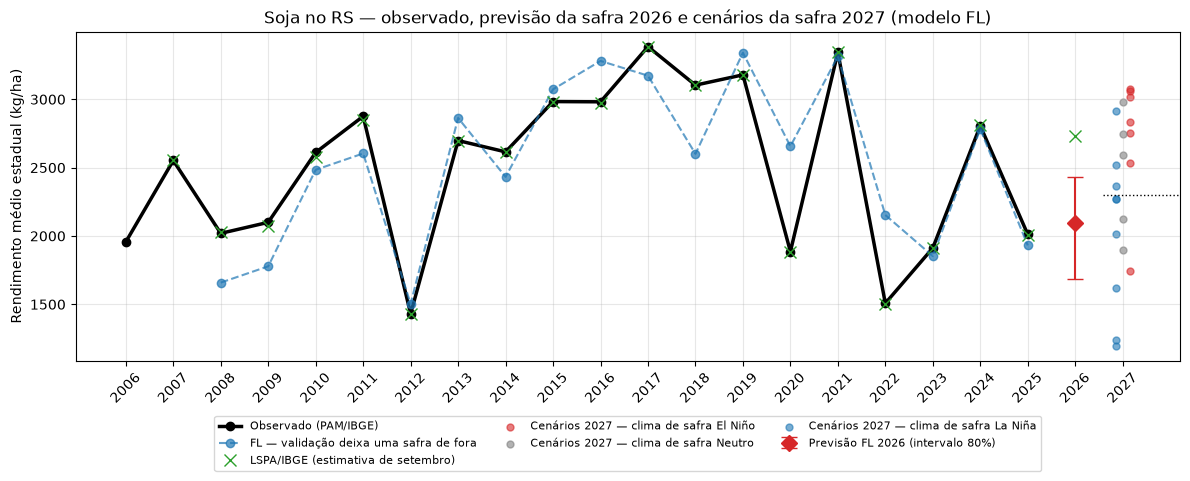

In [13]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pam_estado.loc[PRIMEIRA_SAFRA:].index, pam_estado.loc[PRIMEIRA_SAFRA:], "k-o", lw=2.5,
        label="Observado (PAM/IBGE)")
ax.plot(estado_loyo.index, estado_loyo[FINAL], "--o", color="tab:blue", alpha=0.7,
        label="FL — validação deixa uma safra de fora")
ax.plot(lspa_set.loc[PRIMEIRA_SAFRA:].index, lspa_set.loc[PRIMEIRA_SAFRA:], "x", color="tab:green", ms=8,
        label="LSPA/IBGE (estimativa de setembro)")
fl26 = previsao_estado.loc[FINAL]
ax.errorbar([SAFRA_PREVISAO], [fl26["previsão (kg/ha)"]],
            yerr=[[fl26["previsão (kg/ha)"] - fl26["intervalo 80% — de"]],
                  [fl26["intervalo 80% — até"] - fl26["previsão (kg/ha)"]]],
            fmt="D", color="tab:red", ms=8, capsize=6, label=f"Previsão FL {SAFRA_PREVISAO} (intervalo 80%)")
col27 = f"FL {SAFRA_PERSPECTIVA} (kg/ha)"
cores = {"El Niño": "tab:red", "Neutro": "tab:grey", "La Niña": "tab:blue"}
for fase, cor in cores.items():
    v = cen.loc[cen["fase do ENOS"] == fase, col27]
    ax.scatter(np.full(len(v), SAFRA_PERSPECTIVA) + {"El Niño": 0.15, "Neutro": 0, "La Niña": -0.15}[fase], v,
               color=cor, alpha=0.6, s=25, label=f"Cenários {SAFRA_PERSPECTIVA} — clima de safra {fase}")
ax.axhline(patamar_2027, xmin=0.93, color="k", lw=1, ls=":")
ax.set_xticks(range(PRIMEIRA_SAFRA, SAFRA_PERSPECTIVA + 1))
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Rendimento médio estadual (kg/ha)")
ax.set_title("Soja no RS — observado, previsão da safra 2026 e cenários da safra 2027 (modelo FL)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout()
plt.show()

## 9. Conclusões

**Validação com as safras publicadas (seção 5).** O FL continua sendo o melhor dos cinco modelos com o patamar calculado só com as safras já publicadas em 31 de março (para 2026, 2020–2024): RMSE médio de 699 kg/ha nas duas validações (626 kg/ha e R² 0,40 no "deixa uma safra de fora"; 772 kg/ha no corte 2021–2025), à frente de H2 (715), F (724), GB (828) e da linha de base (886). A escolha da Etapa 5 fica reconfirmada. Na média estadual, o FL erra em média 244 kg/ha por safra, com correlação de 0,85 com o observado. No corte 2021–2025 os modelos com clima superestimam (viés de cerca de +300 kg/ha), porque quatro das cinco safras do teste foram de seca.

**Safra 2026 (seção 6).** Com o clima de out/2025–mar/2026 do NASA POWER, o FL prevê **2.097 kg/ha** para o estado (intervalo de 80%: 1.685 a 2.430 kg/ha), abaixo do patamar 2020–2024 (2.270 kg/ha). Pelo NASA POWER, 2026 teve chuva abaixo da média em out–nov (161 mm, contra 295 mm) e em dez–fev (281 mm, contra 368 mm), com umidade mínima baixa, e são esses fatores que puxam a previsão para baixo (−284 e −103 kg/ha). O LSPA/IBGE de set/2026, porém, estima **2.734 kg/ha**, e o LSPA de setembro costuma ficar a menos de 10 kg/ha da PAM (diferença média de 7 kg/ha em 2007–2025). **O FL subestimou 2026 em cerca de 640 kg/ha (−23%), fora do intervalo de 80%.** Todos os cinco modelos ficaram abaixo do LSPA. Este é o primeiro teste totalmente fora da amostra do projeto, e ele indica que (a) o clima de 2026 descrito pelo NASA POWER sugere um ano mais seco do que a safra mostrou, e (b) a perspectiva feita no plantio (seção 7, mediana de 2.491 kg/ha e percentil 90 de 2.989 kg/ha) chegou mais perto do resultado do que a previsão com o clima observado. Antes de usar o FL como previsão operacional, vale conferir o clima de 2026 com as estações do INMET (quando o download de 2026 estiver disponível) e com outra reanálise. A PAM de 2026 (set/2027) fecha a comparação por município.

**Perspectiva da safra 2027 (seção 7).** O patamar de 2027 (2021–2025) é de 2.300 kg/ha, ainda baixo por incluir as secas de 2022, 2023 e 2025. Com o clima das 21 safras de 2006–2026 aplicado a esse patamar, o FL dá uma mediana de **2.522 kg/ha** (percentil 10: 1.623; percentil 90: 3.019). Considerando só os 7 cenários de El Niño, fase esperada para o verão de 2026/27 (ONI de +2,2 em JAS/2026), a mediana sobe para **2.831 kg/ha** (de 1.746 a 3.077 kg/ha). Ou seja, sob El Niño a safra 2027 tende a ficar acima do patamar e perto das boas safras recentes (2021, 2024). O risco de quebra é menor, mas não nulo: o cenário de 2020, classificado como El Niño, ainda deu 1.746 kg/ha. Como o FL subestimou 2026, essa perspectiva pode estar pessimista. Por município, a perspectiva está em `dataset/processed/perspectiva_safra_2027_municipio.csv`.

**Próximo passo.** A previsão de 2027 propriamente dita sai em abril/2027: basta baixar o clima de out/2026 a mar/2027 (`python dataset/baixar_nasa_power.py 20261001 20270331 nasa_power_rs_2027.csv`), incluir o arquivo na seção 2 e trocar `SAFRA_PREVISAO` para 2027.